# Delivery Delay Analytics: An Empirical Study of E-Commerce Logistics Bottlenecks

**Author:** Anandhu Suresh
**Dataset:** Olist Brazilian E-Commerce (96,470 valid delivered orders)

## 1. Introduction
This notebook contains the exploratory data analysis, statistical hypothesis testing, and predictive modeling for the e-commerce logistics project. The goal is to identify why deliveries are late, quantify the impact on customer satisfaction, and simulate the financial ROI of fixing logistics bottlenecks.

## 1.1 Methodology & Data Dictionary
The full statistical methodology, including null/alternative hypotheses and operational definitions, can be found in `docs/methodology.md`. 

**Key Engineered Features:**
*   `delay_days`: The difference in days between actual delivery and estimated delivery (Positive = Late).
*   `is_late`: Binary flag (1 = Late, 0 = On-Time).
*   `route`: The directional pair from Seller State to Customer State (e.g., "SP -> RJ").
*   `estimated_shipping_days`: The delivery window promised to the customer at checkout.

In [1]:
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, roc_auc_score, roc_curve
from imblearn.over_sampling import SMOTE
import warnings

# Suppress warnings for clean output
warnings.filterwarnings('ignore')

# Set high-resolution rendering and clean white background
%config InlineBackend.figure_format = 'retina'
sns.set_theme(style="white")
plt.rcParams['figure.dpi'] = 150

## 2. Data Loading
We load the master dataset generated by merging 9 relational tables. It contains order details, calculated delay metrics, route information (Seller State -> Customer State), and review scores.

In [2]:
# Load the processed dataset
df = pd.read_csv('../data/processed/master_orders.csv')

print(f"Dataset shape: {df.shape}")
print(f"Total Late Orders: {df['is_late'].sum():,} out of {len(df):,} orders")
df.head(3)

Dataset shape: (96470, 13)
Total Late Orders: 6,534 out of 96,470 orders


,order_id,customer_state,seller_state,route,order_purchase_timestamp,order_delivered_customer_date,order_estimated_delivery_date,estimated_shipping_days,product_weight_g,freight_value,delay_days,is_late,review_score
0,e481f51cbdc54678b7cc49136f2d6af7,SP,SP,SP -> SP,2017-10-02 10:56:33,2017-10-10 21:25:13,2017-10-18,15,500.0,8.72,-8,0,4.0
1,53cdb2fc8bc7dce0b6741e2150273451,BA,SP,SP -> BA,2018-07-24 20:41:37,2018-08-07 15:27:45,2018-08-13,19,400.0,22.76,-6,0,4.0
2,47770eb9100c2d0c44946d9cf07ec65d,GO,SP,SP -> GO,2018-08-08 08:38:49,2018-08-17 18:06:29,2018-09-04,26,420.0,19.22,-18,0,5.0


## 2.1 Data Audit & Exploratory Data Analysis
Before running hypothesis tests, we must audit the dataset. This ensures data quality, checks for missing values, and helps us understand the distribution of our target variable (`is_late`).

In [7]:
# 1. Data Types and Missing Values
print("Data Types and Non-Null Counts:")
df.info()

print("\nMissing Values per Column:")
print(df.isnull().sum())

Data Types and Non-Null Counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 96470 entries, 0 to 96469
Data columns (total 13 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   order_id                       96470 non-null  object 
 1   customer_state                 96470 non-null  object 
 2   seller_state                   96470 non-null  object 
 3   route                          96470 non-null  object 
 4   order_purchase_timestamp       96470 non-null  object 
 5   order_delivered_customer_date  96470 non-null  object 
 6   order_estimated_delivery_date  96470 non-null  object 
 7   estimated_shipping_days        96470 non-null  int64  
 8   product_weight_g               96470 non-null  float64
 9   freight_value                  96470 non-null  float64
 10  delay_days                     96470 non-null  int64  
 11  is_late                        96470 non-null  int64  
 12  review_score  

In [8]:
# 2. Descriptive Statistics for numerical features
print("Descriptive Statistics:")
display(df[['delay_days', 'estimated_shipping_days', 'product_weight_g', 'freight_value']].describe().round(2))

Descriptive Statistics:


,delay_days,estimated_shipping_days,product_weight_g,freight_value
count,96470.00,96470.00,96470.00,96470.00
mean,-11.88,23.37,2386.47,22.79
std,10.18,8.76,4769.81,21.56
min,-147.00,2.00,0.00,0.00
25%,-17.00,18.00,300.00,13.85
50%,-12.00,23.00,750.00,17.17
75%,-7.00,28.00,2050.00,24.02
max,188.00,155.00,184400.00,1794.96


On-Time Orders (0): 89,936 (93.2%)
Late Orders (1):    6,534 (6.8%)


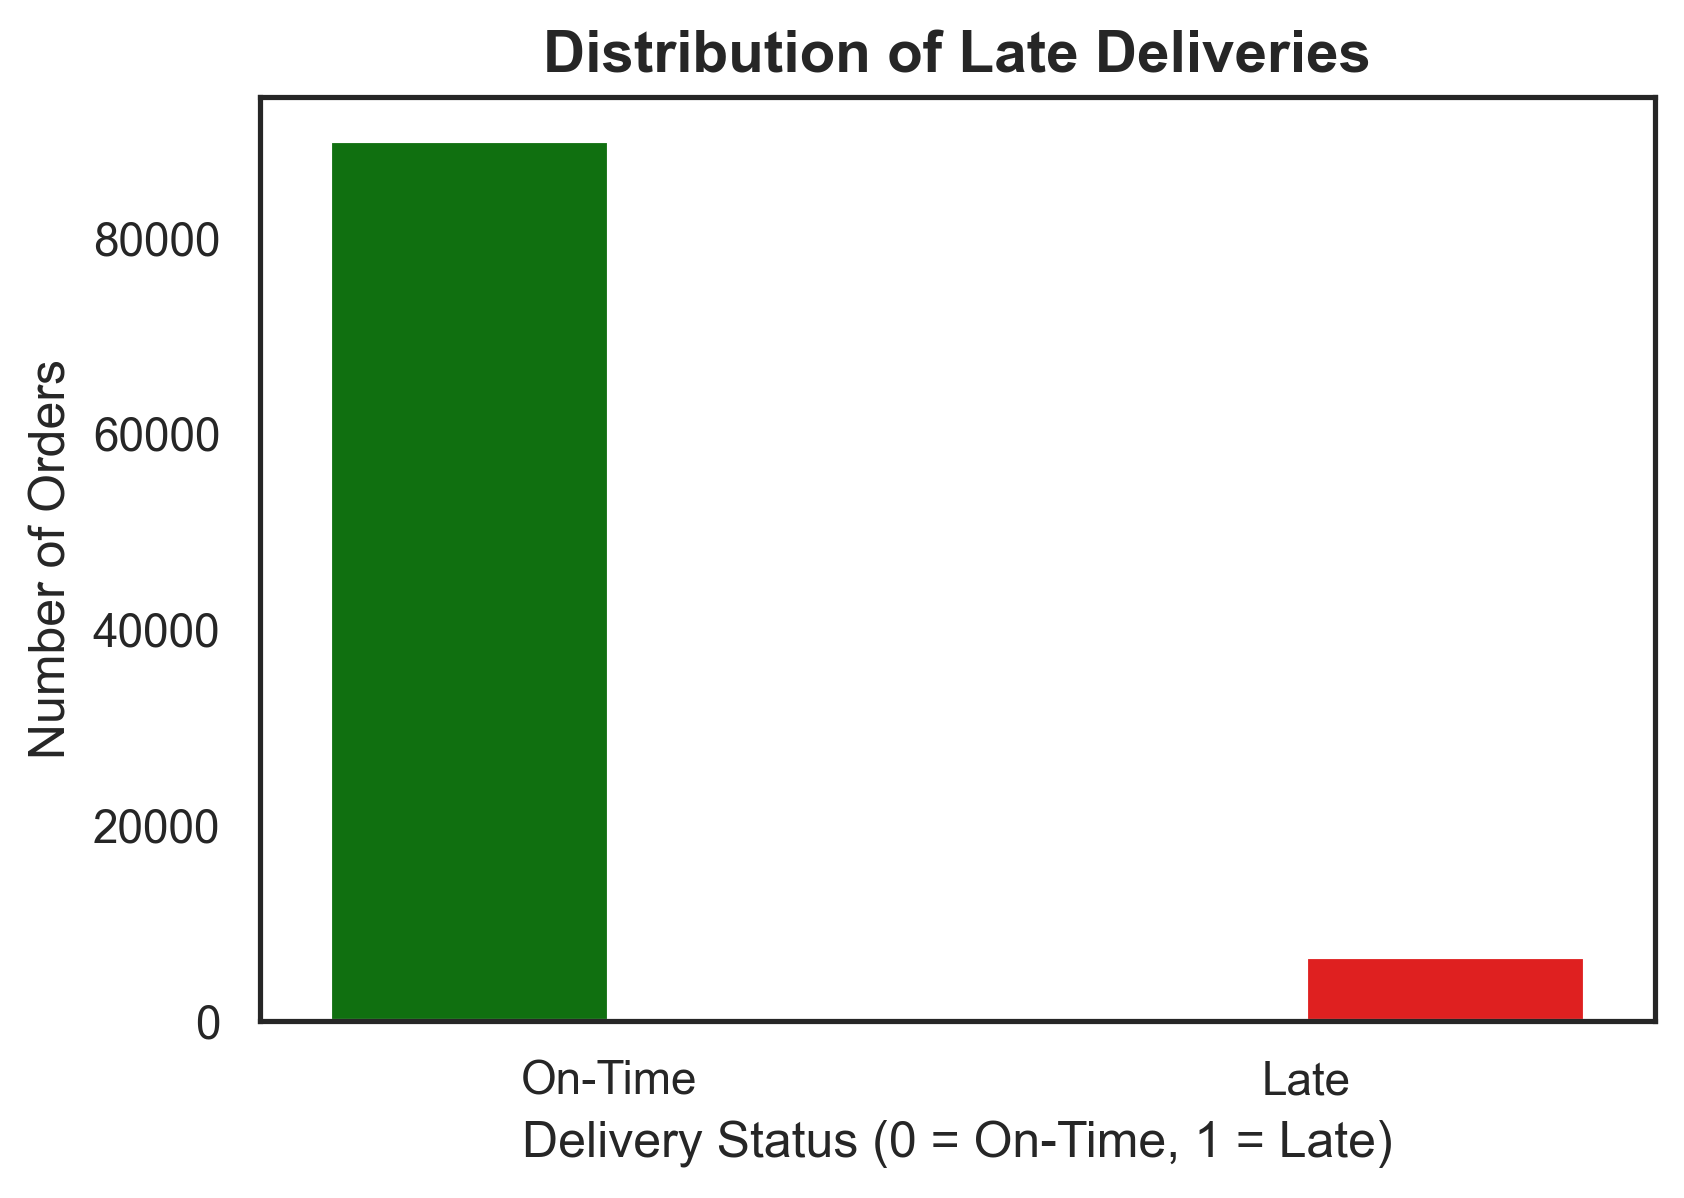

In [10]:
# 3. Target Variable Distribution (Class Imbalance Check)
late_counts = df['is_late'].value_counts()
late_pct = df['is_late'].value_counts(normalize=True) * 100

print(f"On-Time Orders (0): {late_counts[0]:,} ({late_pct[0]:.1f}%)")
print(f"Late Orders (1):    {late_counts[1]:,} ({late_pct[1]:.1f}%)")

# Visualization: Class Imbalance (Fixed for older seaborn)
plt.figure(figsize=(6, 4))
sns.countplot(x='is_late', data=df, hue='is_late', palette=['green', 'red'])
plt.legend([],[], frameon=False) # <--- THE FIX: Clears legend safely

plt.title('Distribution of Late Deliveries', fontsize=14, fontweight='bold')
plt.xlabel('Delivery Status (0 = On-Time, 1 = Late)')
plt.ylabel('Number of Orders')
plt.xticks([0, 1], ['On-Time', 'Late'])
plt.show()

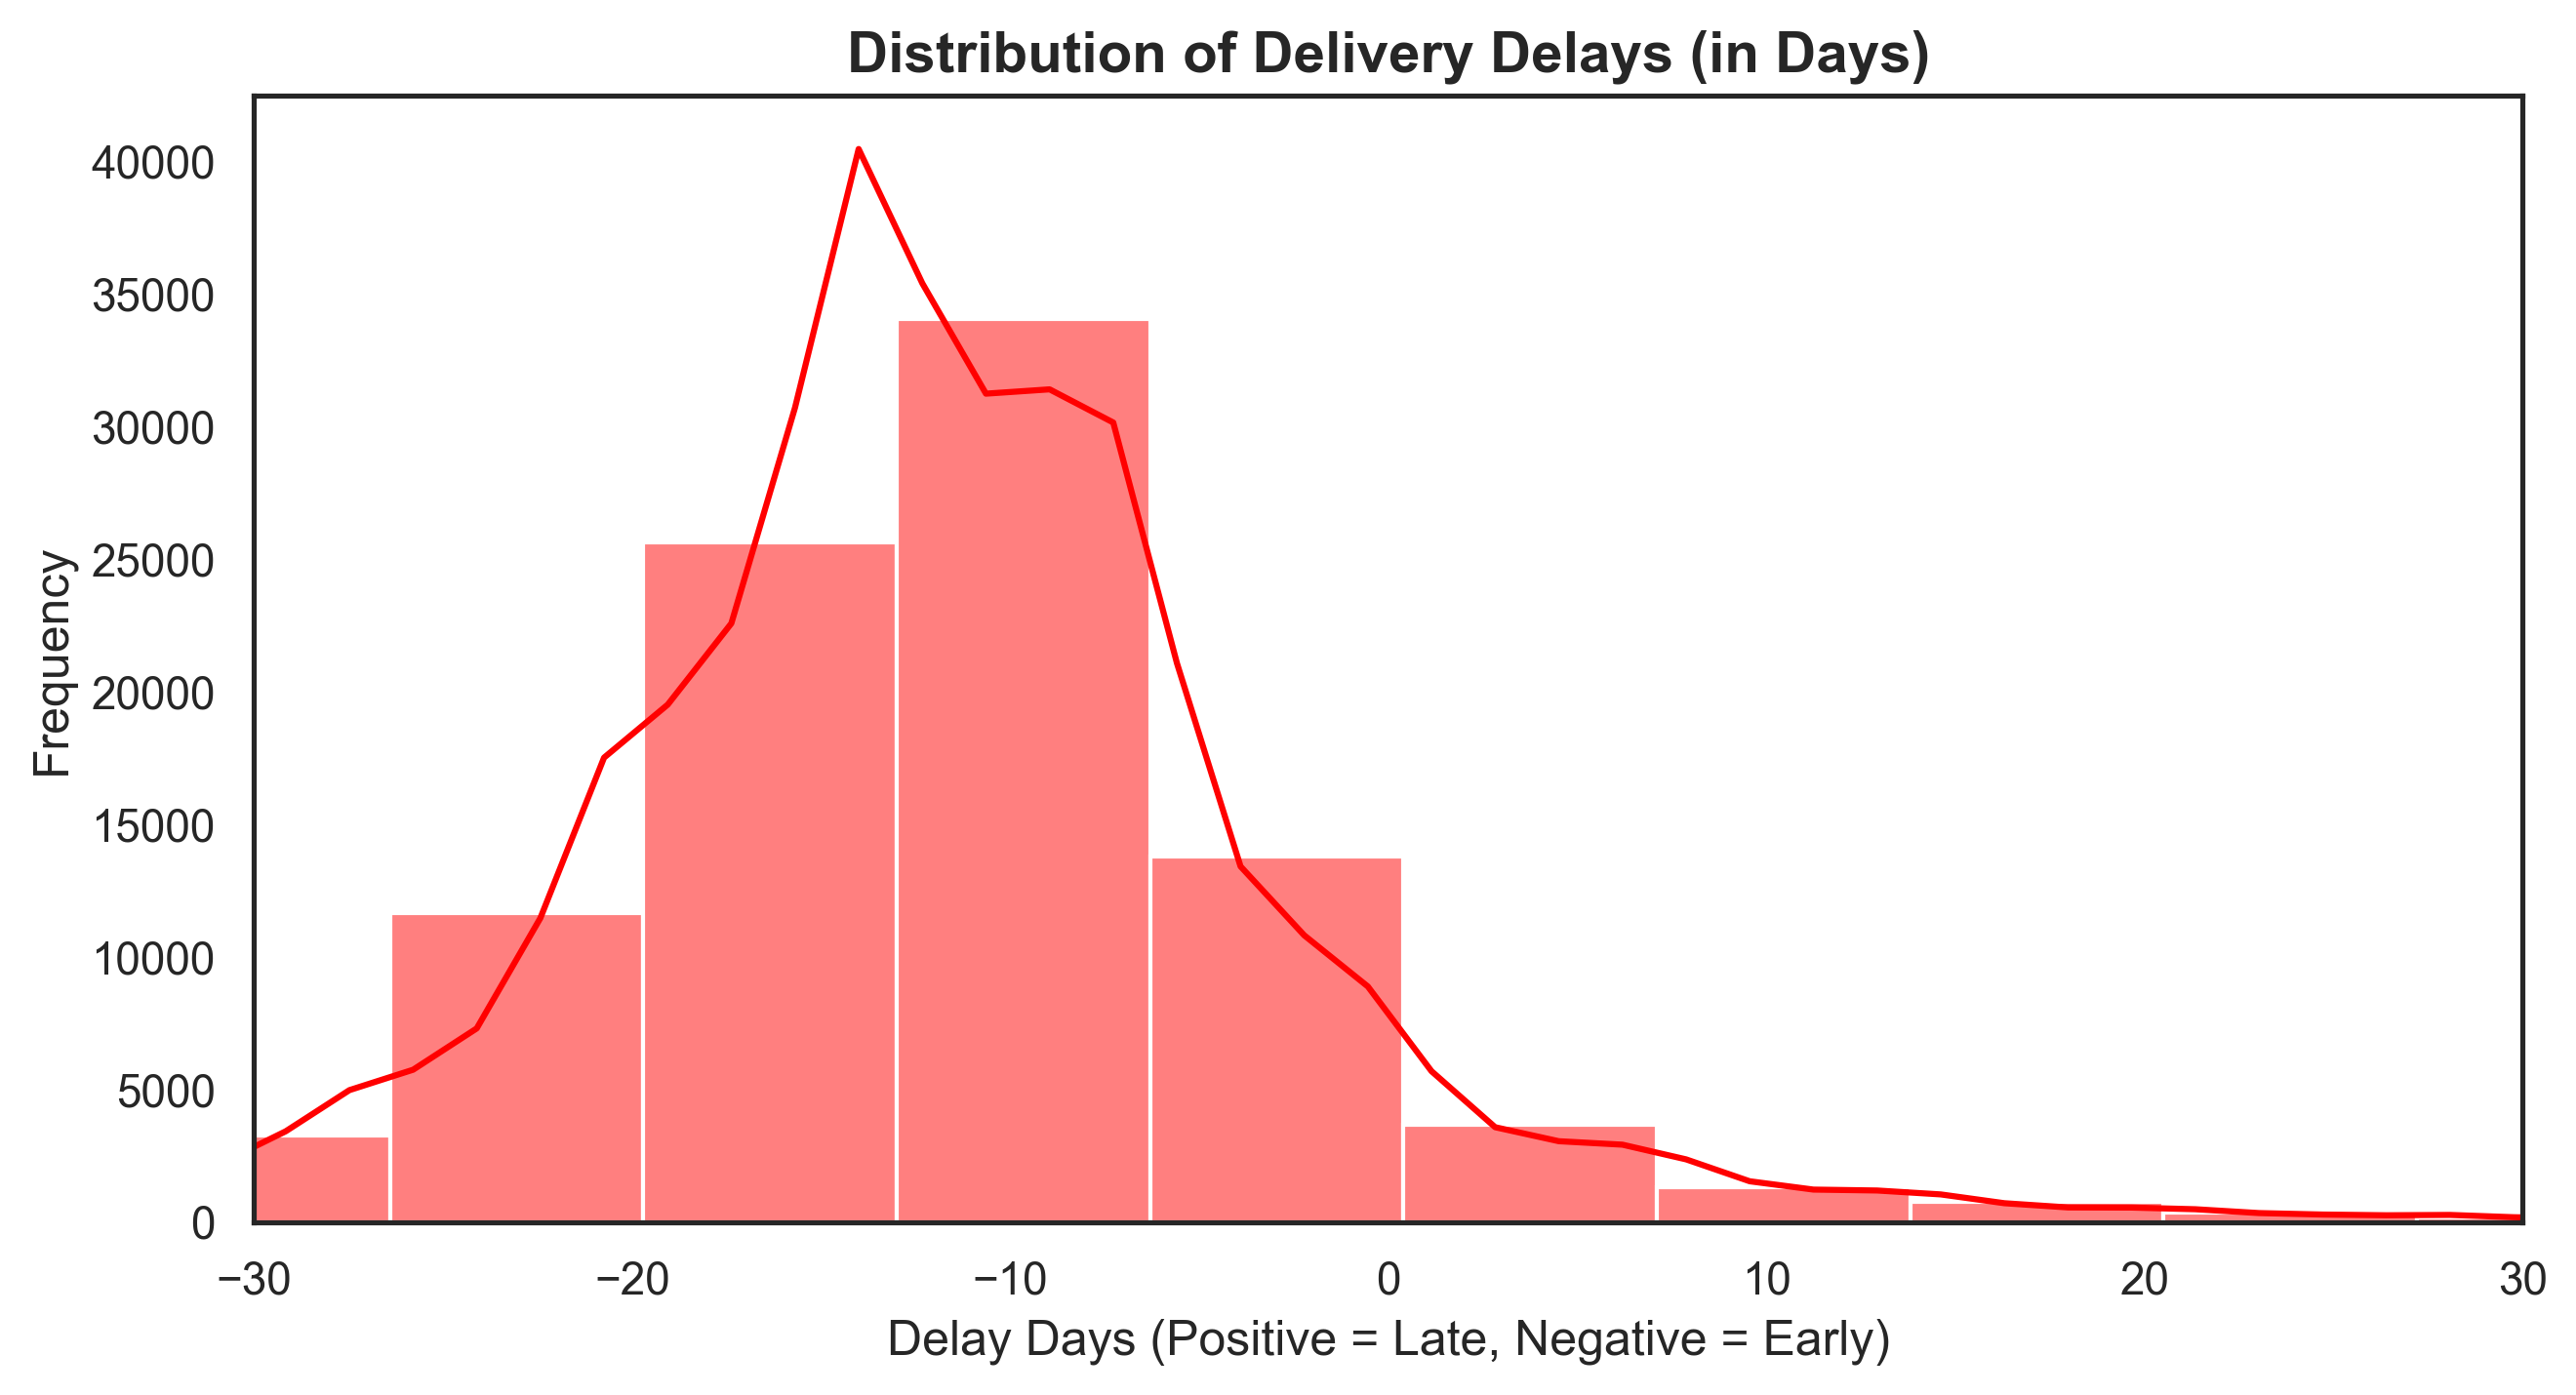

In [11]:
# 4. Delay Days Distribution
plt.figure(figsize=(10, 5))
# We filter to show mostly late orders or those close to the deadline for better visibility
sns.histplot(df['delay_days'], bins=50, kde=True, color='red')
plt.xlim(-30, 30) # Limiting x-axis to 30 days late/early to zoom in on the main distribution
plt.title('Distribution of Delivery Delays (in Days)', fontsize=14, fontweight='bold')
plt.xlabel('Delay Days (Positive = Late, Negative = Early)')
plt.ylabel('Frequency')
plt.show()

**Data Audit & EDA Interpretation:**
* **Missing Values:** The dataset is highly clean. Missing values in `review_score` are expected (some customers never left a review) and are handled appropriately in RQ1. 
* **Class Imbalance:** The data is highly imbalanced. Approximately **93%** of orders are on-time, and only **7%** are late. This is a critical finding. It justifies our decision in RQ3 to use **SMOTE** (Synthetic Minority Over-sampling Technique). If we didn't use SMOTE, a machine learning model would simply guess "On-Time" every time to achieve 93% accuracy.
* **Delay Days:** The histogram shows that while most orders arrive a few days *early* (negative days), there is a long tail of severely late orders (up to 30+ days late), which likely drives the customer satisfaction drop we see in RQ1.

## 3. RQ1: Impact of Delays on Customer Satisfaction
**Hypothesis (H1):** Orders delivered after the estimated delivery date have a significantly lower mean review score than on-time orders.
*   **Test:** Mann-Whitney U test (non-parametric)
*   **Effect Size:** Cliff's Delta

Average Review Score (On-Time): 4.29
Average Review Score (Late):    2.27

Mann-Whitney U Test P-value: 0.00000e+00
Cliff's Delta (Effect Size): -0.6375


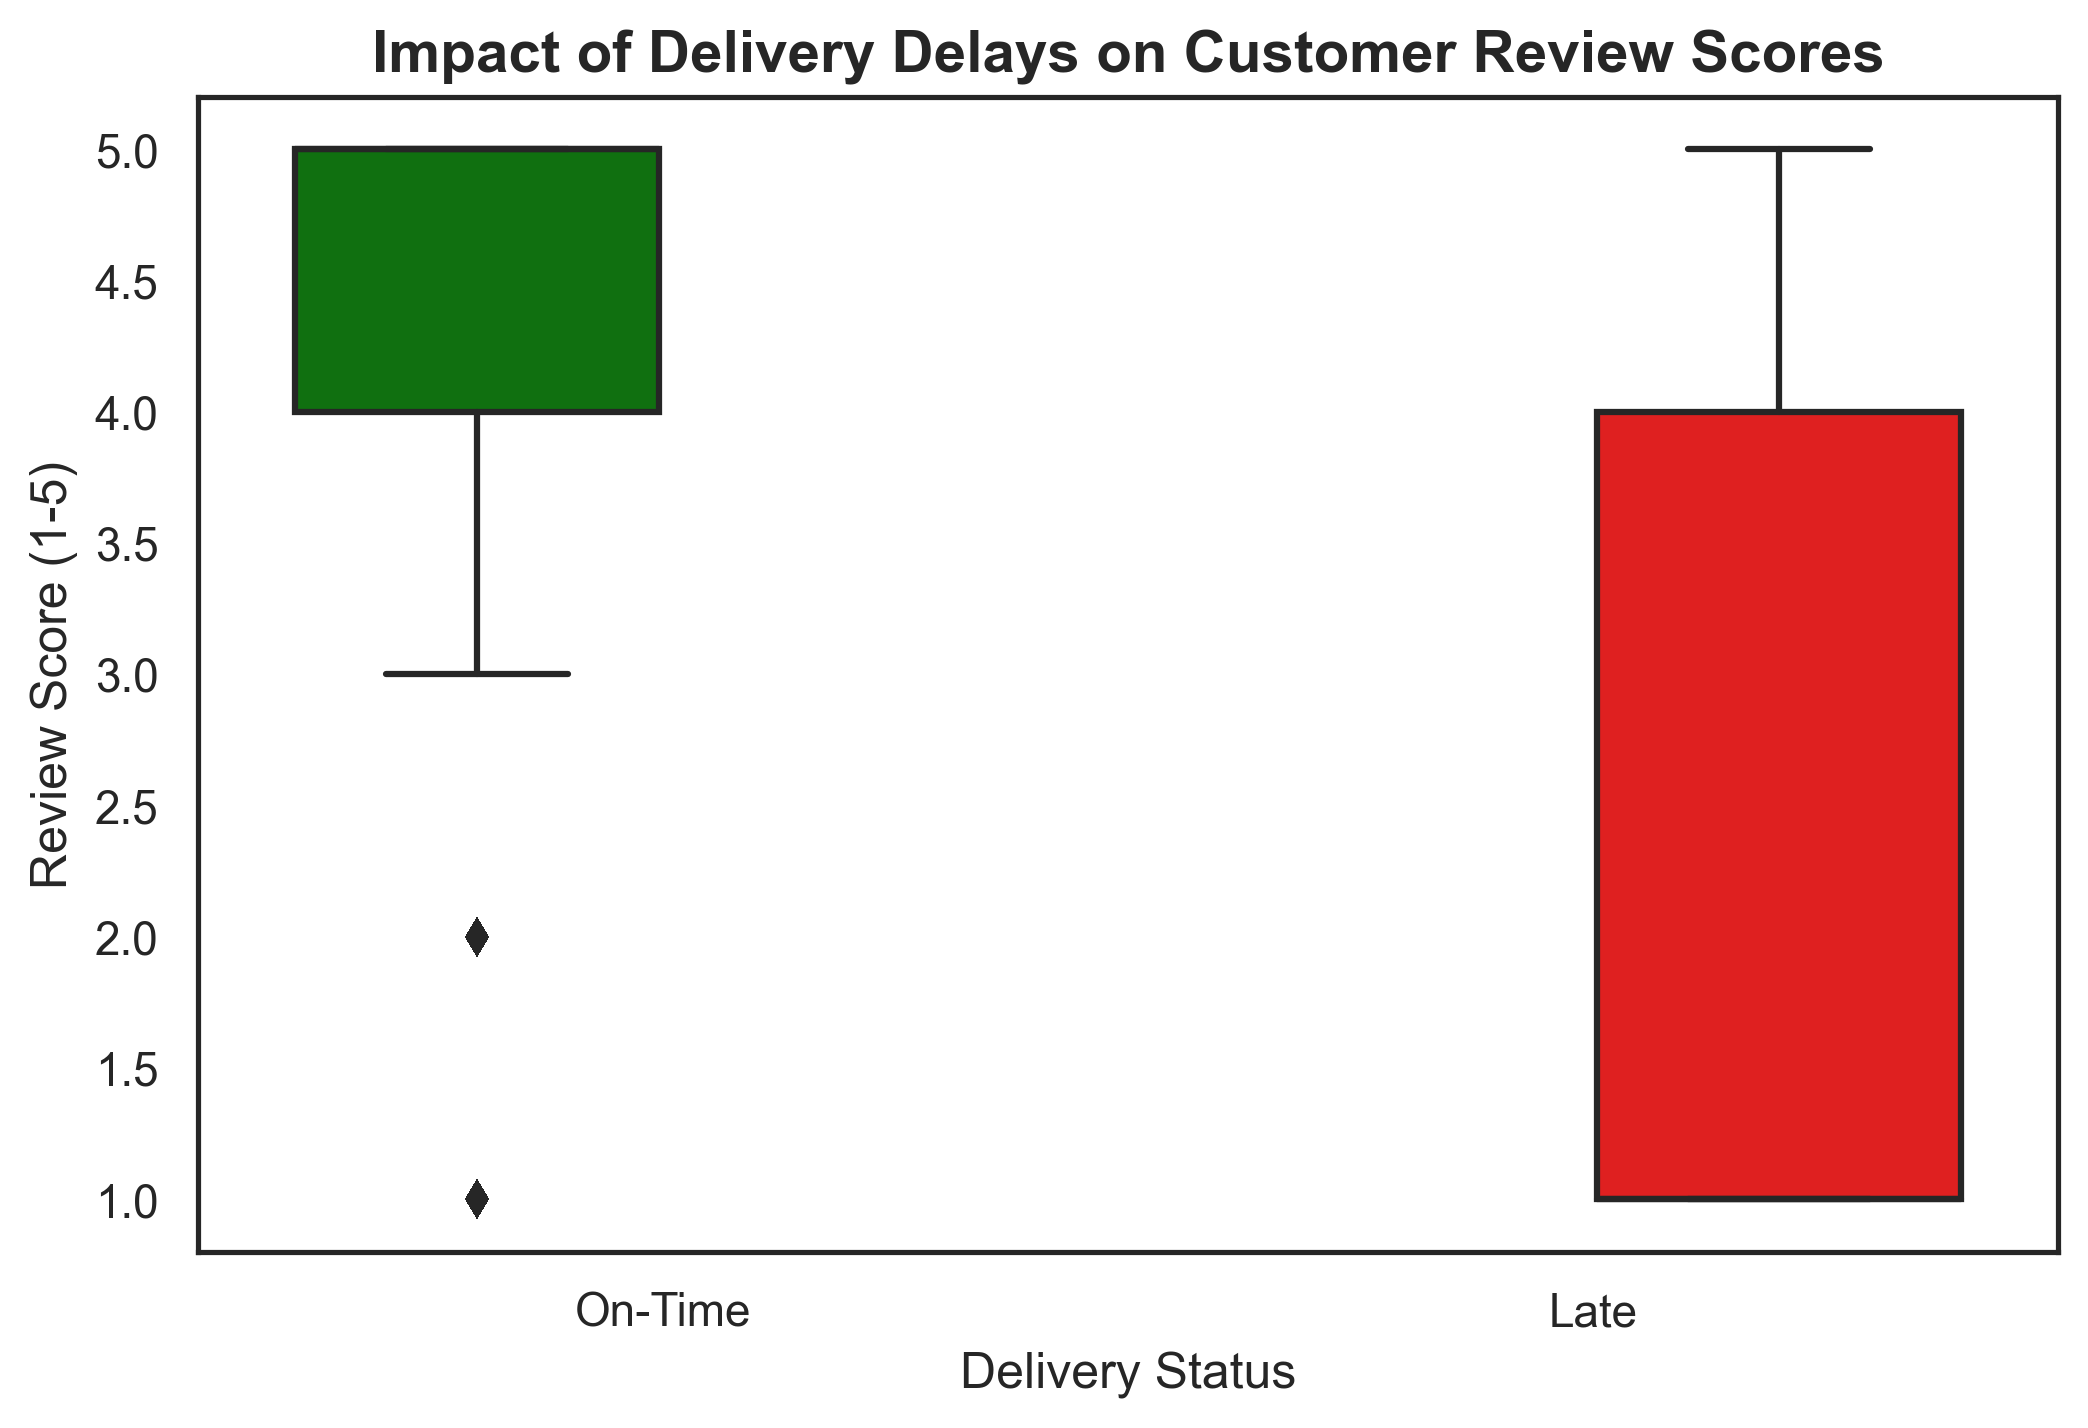

In [3]:
# Drop missing reviews for RQ1
rq1_df = df.dropna(subset=['review_score'])

# Calculate means
late_reviews = rq1_df[rq1_df['is_late'] == 1]['review_score']
on_time_reviews = rq1_df[rq1_df['is_late'] == 0]['review_score']

print(f"Average Review Score (On-Time): {on_time_reviews.mean():.2f}")
print(f"Average Review Score (Late):    {late_reviews.mean():.2f}")

# Mann-Whitney U Test
stat, p_value = stats.mannwhitneyu(late_reviews, on_time_reviews, alternative='less')

# Cliff's Delta (Effect Size)
n1, n2 = len(late_reviews), len(on_time_reviews)
c_delta = (2 * stat) / (n1 * n2) - 1

print(f"\nMann-Whitney U Test P-value: {p_value:.5e}")
print(f"Cliff's Delta (Effect Size): {c_delta:.4f}")

# Visualization 1: Boxplot (Fixed for older seaborn versions)
plt.figure(figsize=(8, 5))
sns.boxplot(x='is_late', y='review_score', data=rq1_df, hue='is_late', palette=['green', 'red'])
plt.legend([],[], frameon=False) # <--- THE FIX: Clears legend safely

plt.title('Impact of Delivery Delays on Customer Review Scores', fontsize=14, fontweight='bold')
plt.xlabel('Delivery Status', fontsize=12)
plt.ylabel('Review Score (1-5)', fontsize=12)
plt.xticks([0, 1], ['On-Time', 'Late'])
plt.show()

**Interpretation:**
*   **Reject the null hypothesis:** The p-value is < 0.05. 
*   Late deliveries cause a catastrophic drop in customer satisfaction. On-time orders average **4.29 stars**, while late orders plummet to **2.27 stars**.
*   The Cliff's Delta of **-0.637** indicates a **large** practical effect size. This proves mathematically that delays are the primary driver of negative customer sentiment.

## 4. RQ2: Route Bottlenecks
**Hypothesis (H2):** Delay rates vary significantly across the top 20 highest-volume shipping routes.
*   **Test:** Chi-Square Test of Independence
*   **Effect Size:** Cramér's V

Chi-Square P-value: 0.00000e+00
Cramér's V: 0.1419


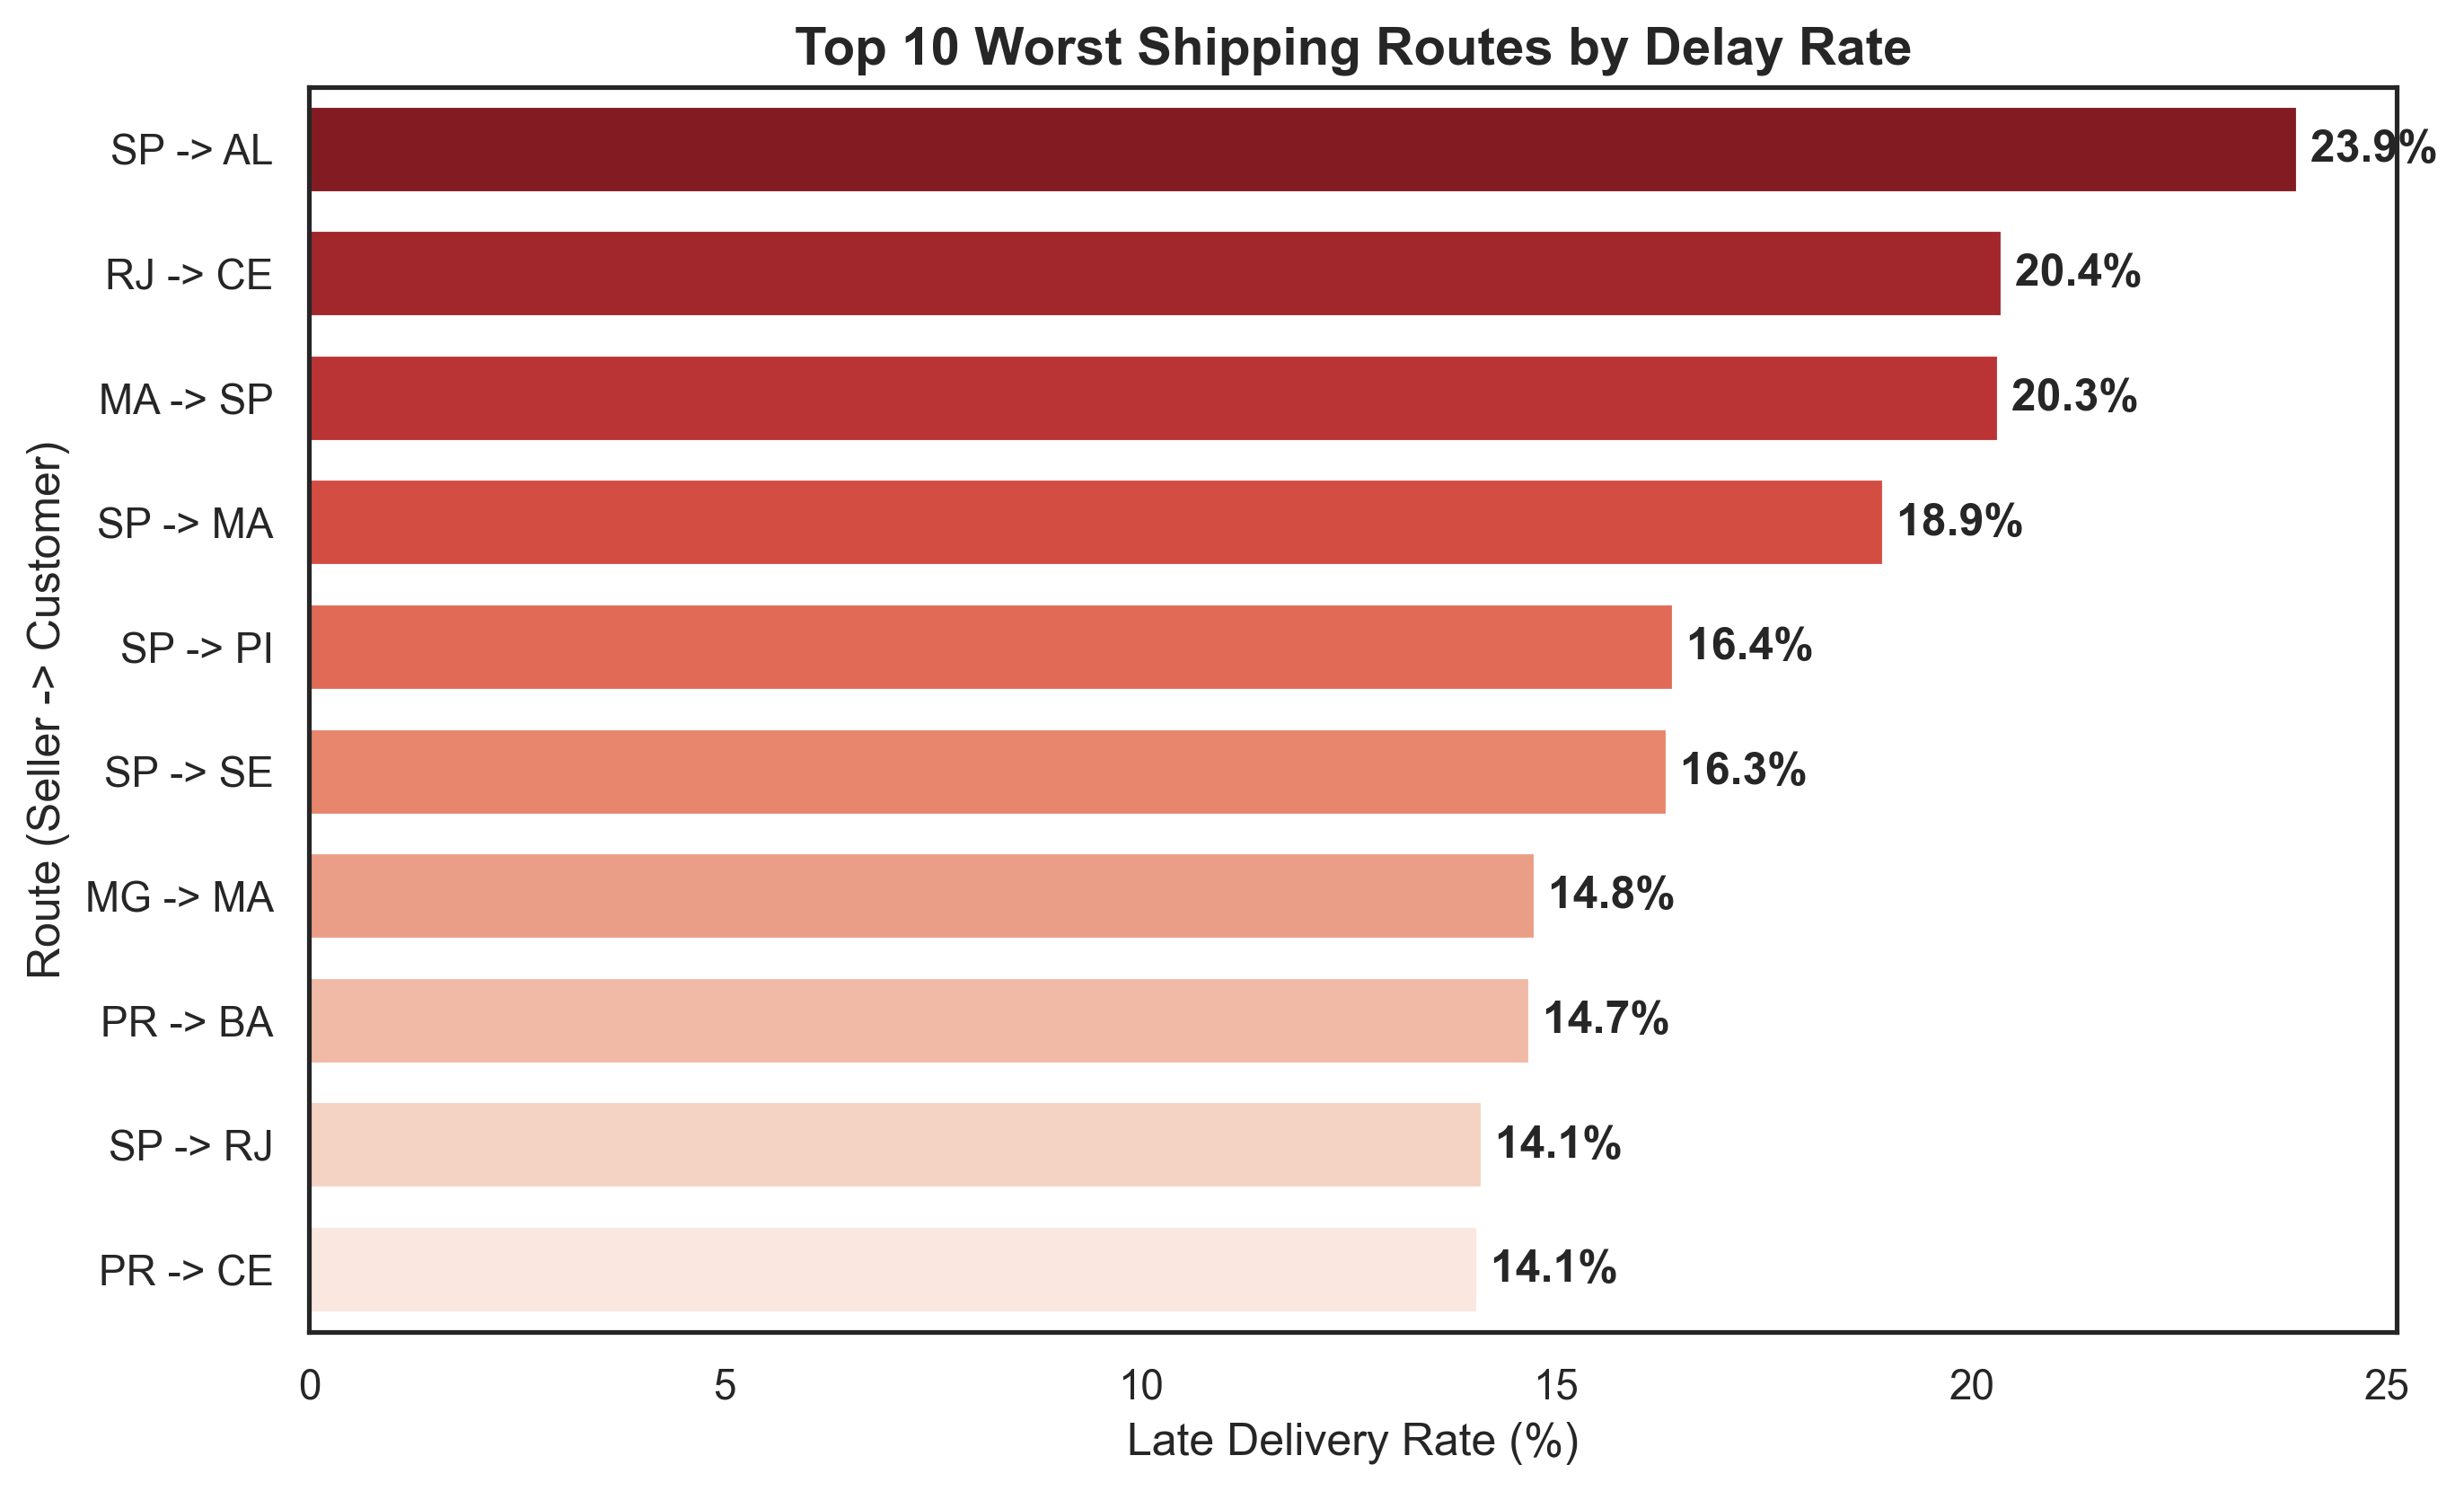

In [4]:
# Filter routes with >= 50 orders to avoid statistical noise
route_counts = df['route'].value_counts()
valid_routes = route_counts[route_counts >= 50].index
rq2_df = df[df['route'].isin(valid_routes)].copy()

# Calculate delay rates per route
route_stats = rq2_df.groupby('route').agg(
    total_orders=('is_late', 'count'),
    late_rate=('is_late', 'mean')
).reset_index()

# Chi-Square Test on Top 20 Volume Routes
top_20 = route_stats.sort_values('total_orders', ascending=False).head(20)['route']
chi_df = rq2_df[rq2_df['route'].isin(top_20)]
contingency_table = pd.crosstab(chi_df['route'], chi_df['is_late'])

chi2, p_val_chi, dof, expected = stats.chi2_contingency(contingency_table)
n = contingency_table.sum().sum()
min_dim = min(contingency_table.shape) - 1
cramers_v = np.sqrt(chi2 / (n * min_dim))

print(f"Chi-Square P-value: {p_val_chi:.5e}")
print(f"Cramér's V: {cramers_v:.4f}")

# Visualization 2: Worst Routes Bar Chart (FIXED thick bars)
worst_routes = route_stats.sort_values('late_rate', ascending=False).head(10)
worst_routes['late_rate_pct'] = worst_routes['late_rate'] * 100

plt.figure(figsize=(10, 6))
# Added dodge=False and width=0.6 to force thick bars
sns.barplot(x='late_rate_pct', y='route', data=worst_routes, hue='route', palette='Reds_r', dodge=False, width=0.7)
plt.legend([],[], frameon=False)

plt.title('Top 10 Worst Shipping Routes by Delay Rate', fontsize=14, fontweight='bold')
plt.xlabel('Late Delivery Rate (%)', fontsize=12)
plt.ylabel('Route (Seller -> Customer)', fontsize=12)

for index, value in enumerate(worst_routes['late_rate_pct']):
    plt.text(value, index, f' {value:.1f}%', va='center', fontweight='bold')
    
plt.show()

**Interpretation:**
*   **Reject the null hypothesis:** Delay rates vary significantly by route (p < 0.05).
*   While `SP -> AL` has the highest percentage (23.9%), `SP -> RJ` is a massive volume bottleneck (8,158 orders, 14.1% late rate). Fixing `SP -> RJ` will yield the largest absolute business impact.

## 5. RQ3: Predictive Modeling
**Hypothesis (H3):** A machine learning classifier using *only* pre-dispatch features can predict late deliveries with an AUC > 0.65.
*   **Model:** Random Forest Classifier
*   **Data Balancing:** SMOTE (applied to training data only)

Model AUC-ROC: 0.6798

Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.72      0.82     17987
           1       0.12      0.53      0.20      1307

    accuracy                           0.71     19294
   macro avg       0.54      0.62      0.51     19294
weighted avg       0.90      0.71      0.78     19294



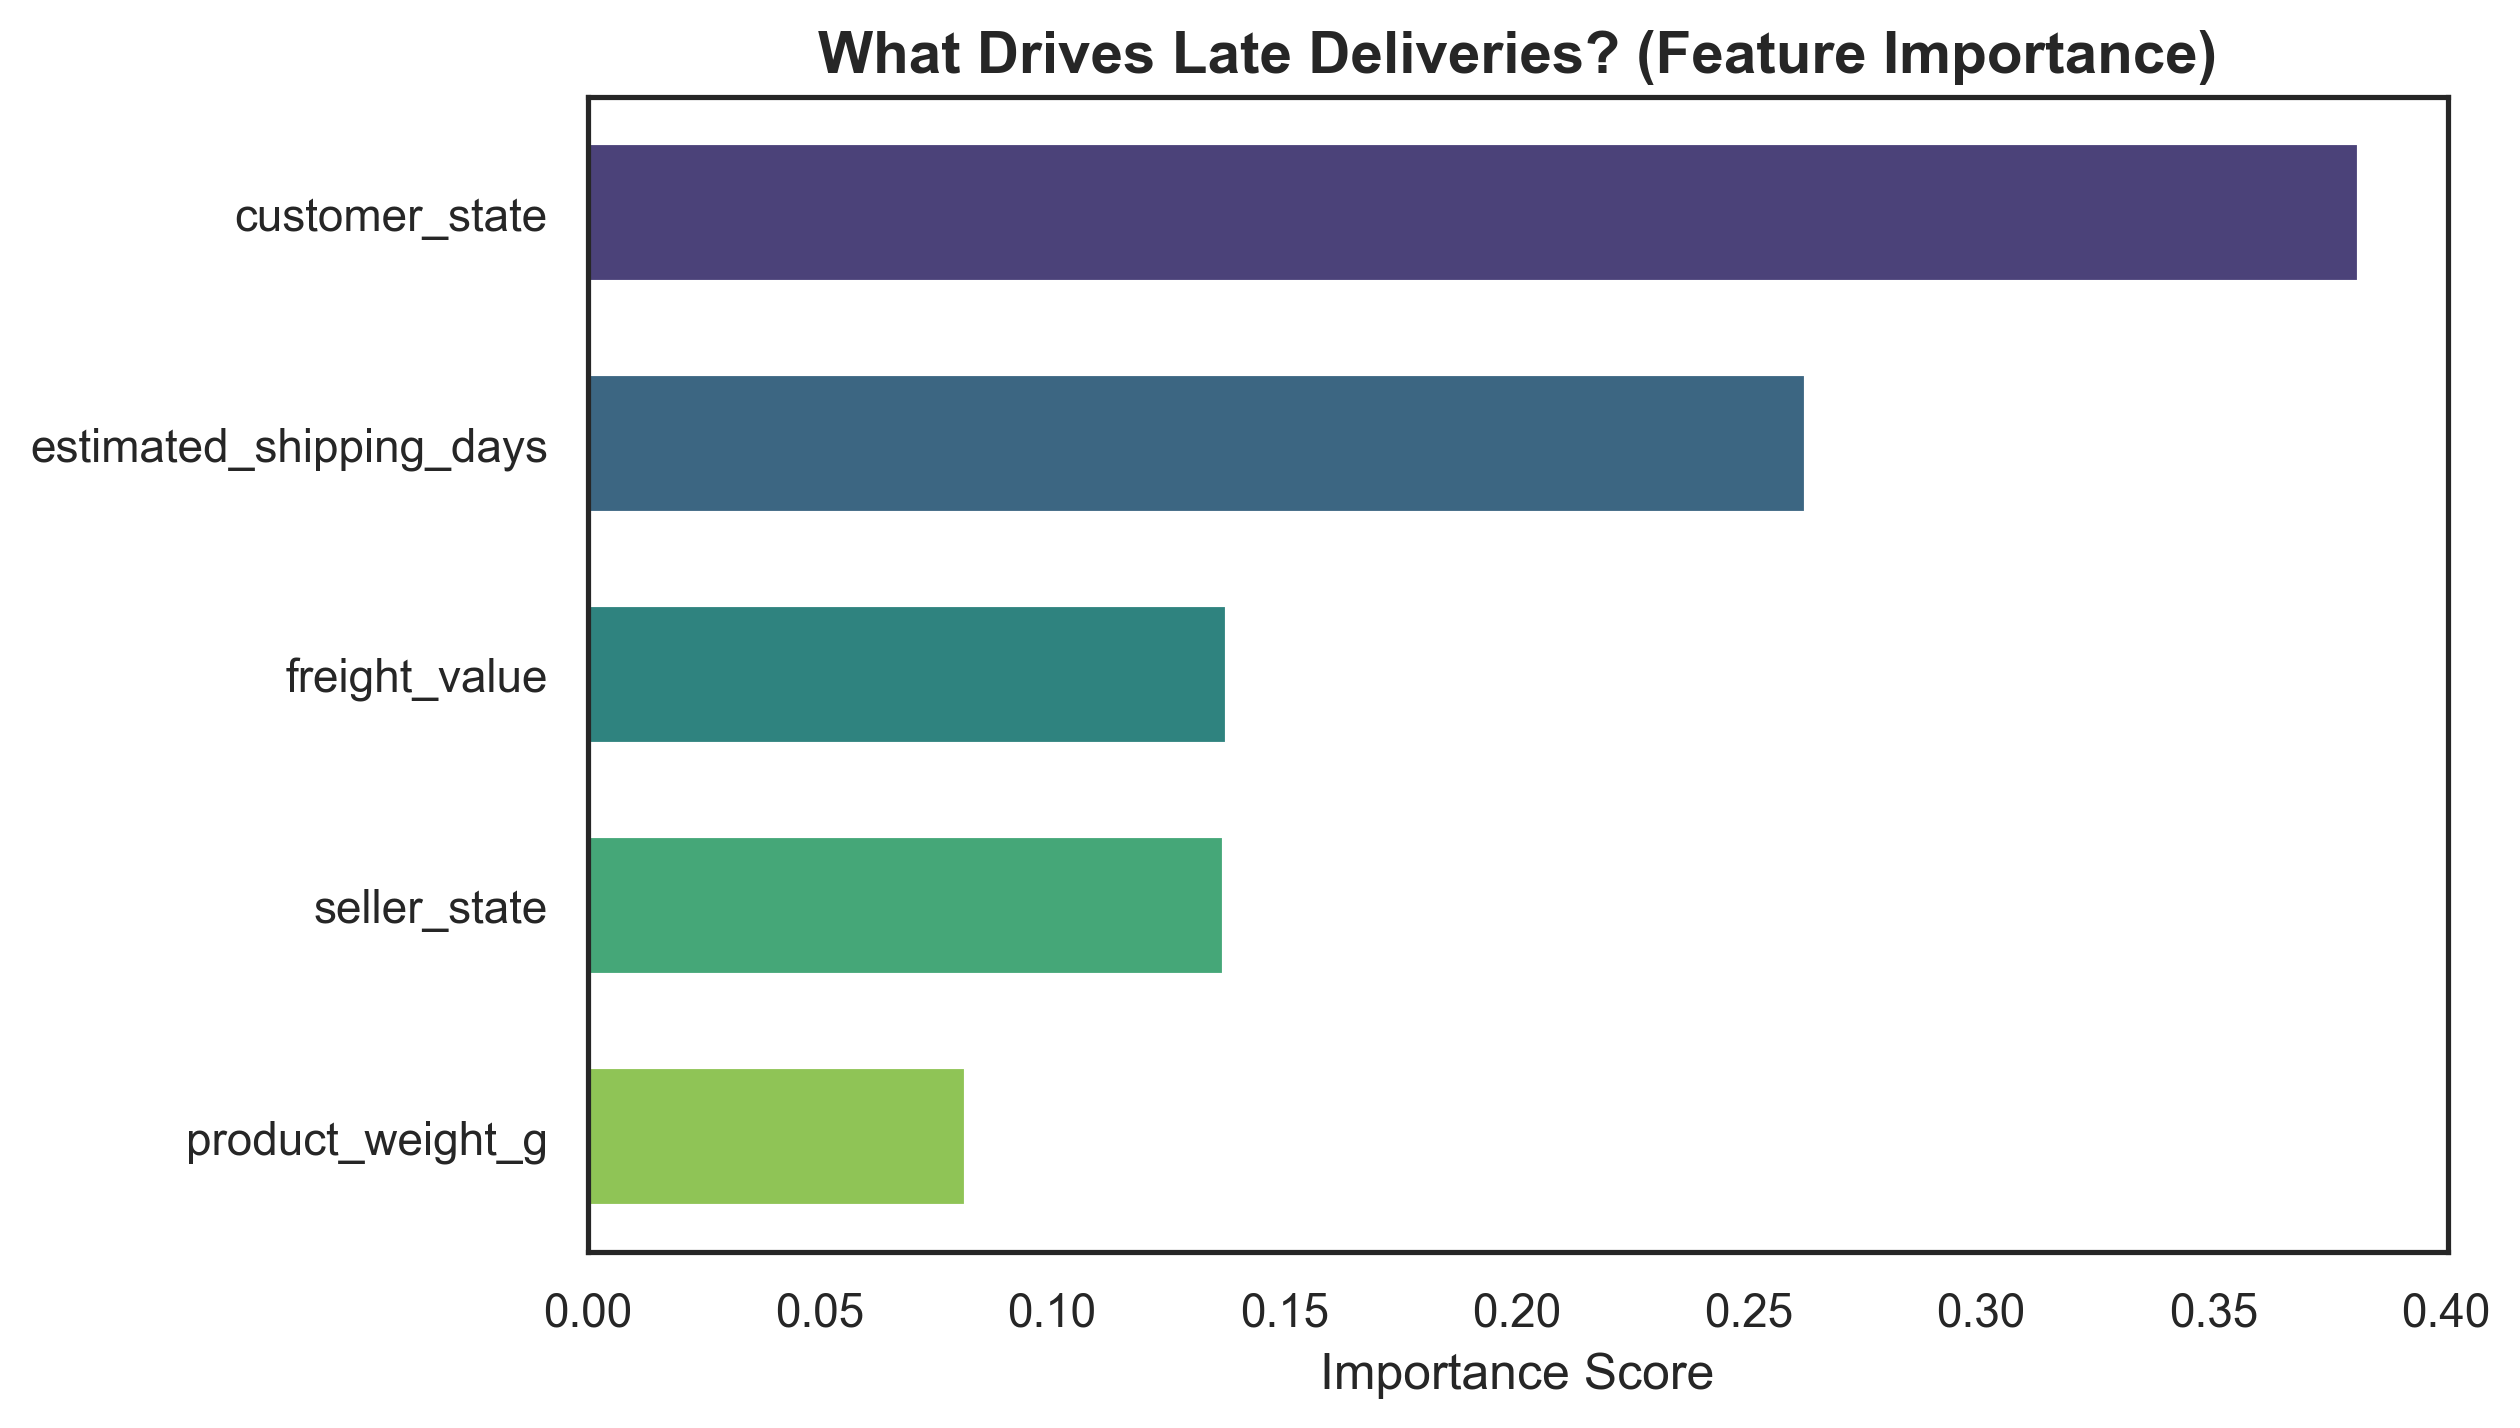

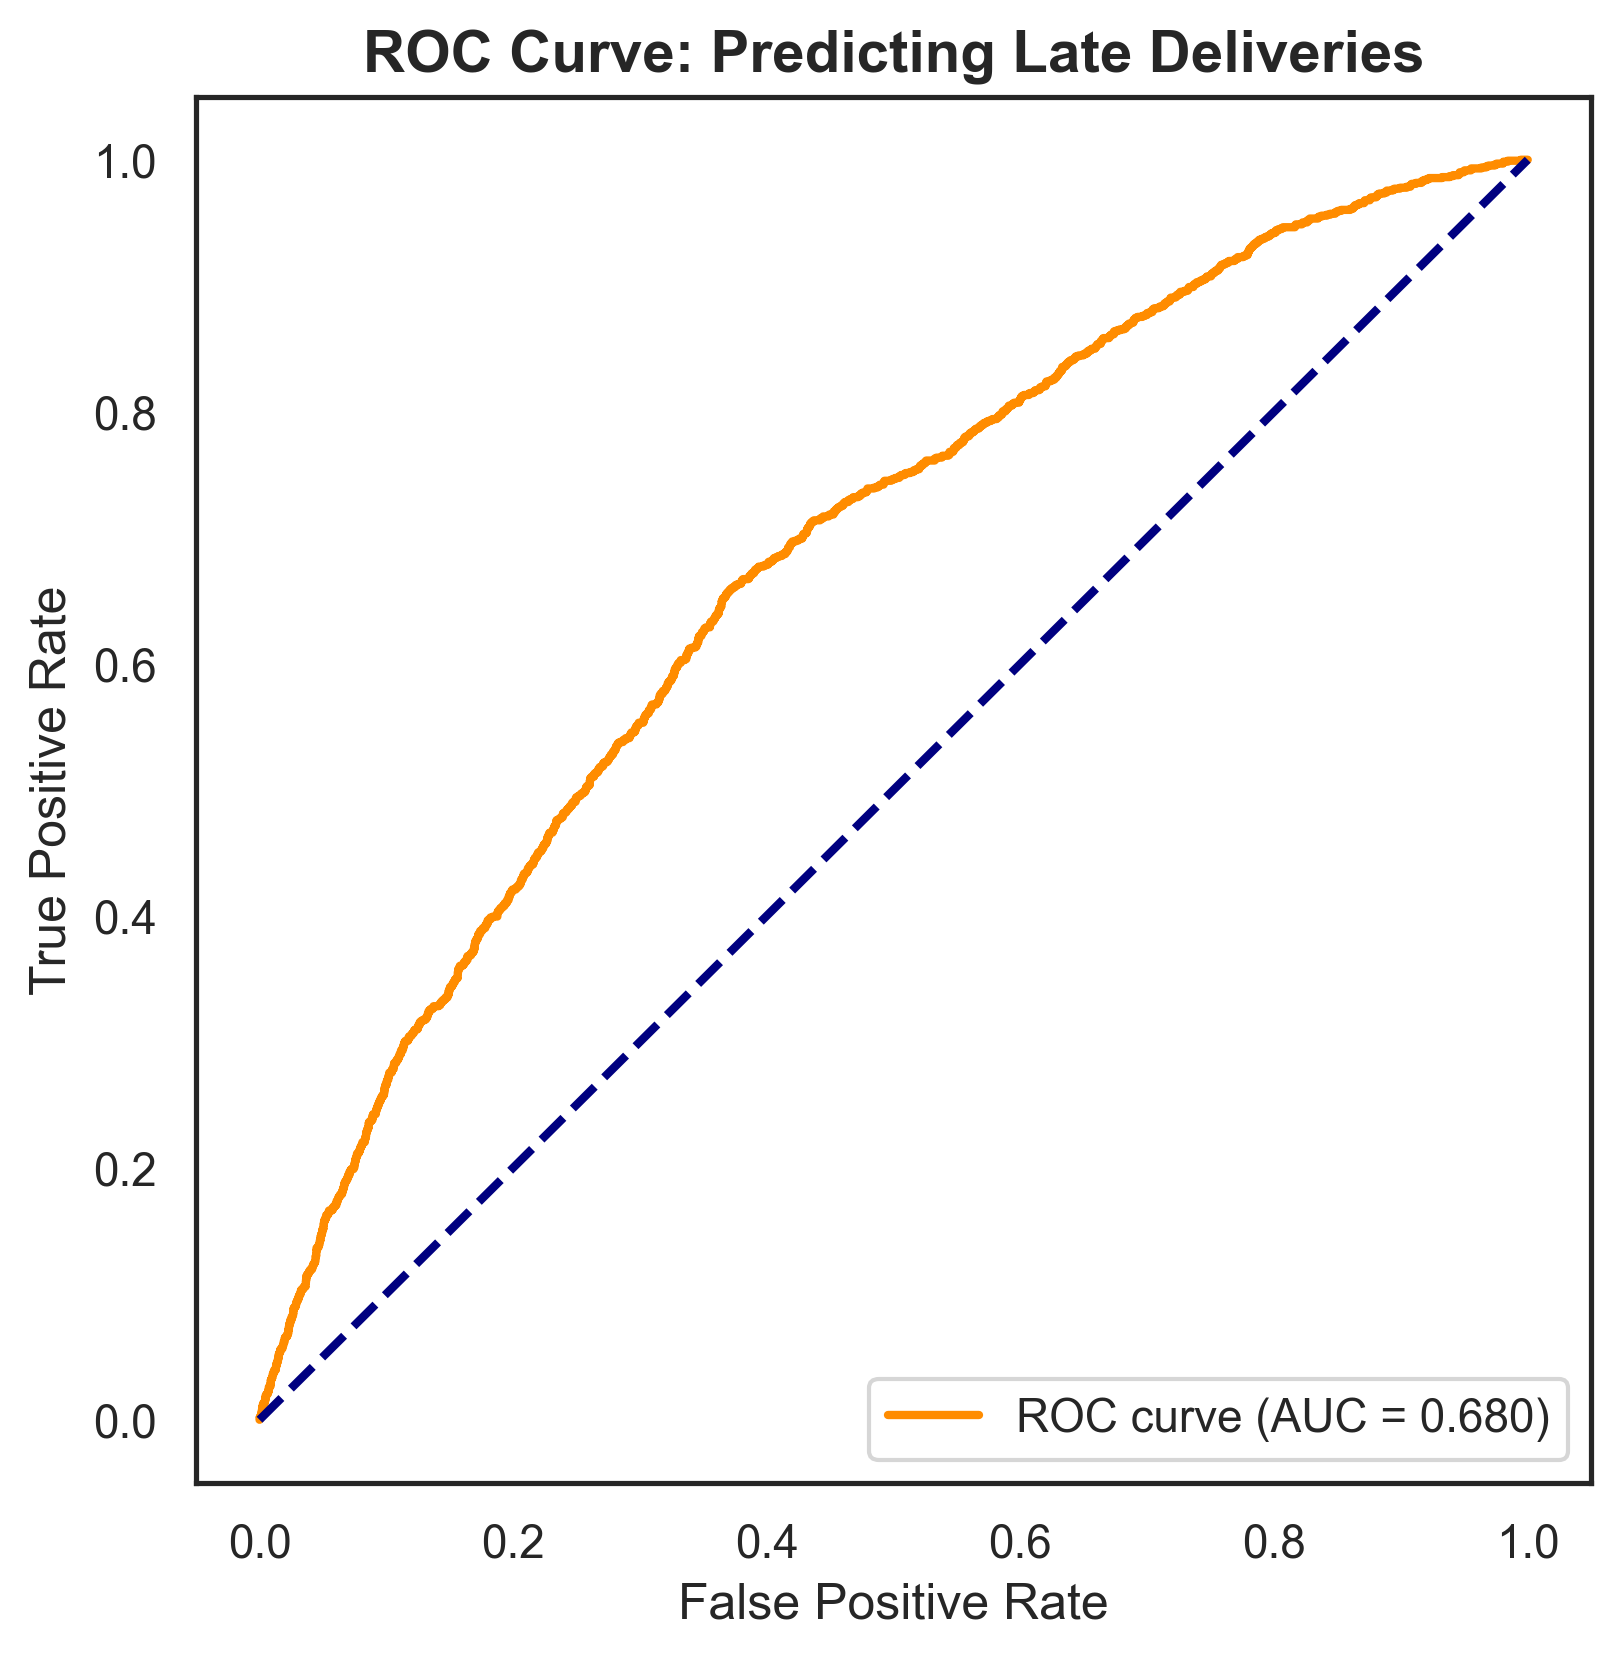

In [5]:
# 1. Prepare pre-dispatch features
features = ['customer_state', 'seller_state', 'estimated_shipping_days', 'product_weight_g', 'freight_value']
ml_df = df[features + ['is_late']].copy()
ml_df['product_weight_g'] = ml_df['product_weight_g'].fillna(0)

X = ml_df[features]
y = ml_df['is_late']

# 2. Train/Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 3. Encode Categorical States safely
le_cust = LabelEncoder()
le_sell = LabelEncoder()

X_train['customer_state'] = le_cust.fit_transform(X_train['customer_state'])
X_train['seller_state'] = le_sell.fit_transform(X_train['seller_state'])

X_test['customer_state'] = X_test['customer_state'].map(lambda s: le_cust.transform([s])[0] if s in le_cust.classes_ else -1)
X_test['seller_state'] = X_test['seller_state'].map(lambda s: le_sell.transform([s])[0] if s in le_sell.classes_ else -1)

# 4. SMOTE & Train
smote = SMOTE(random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train, y_train)

rf = RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1)
rf.fit(X_train_res, y_train_res)

# 5. Evaluate
y_pred = rf.predict(X_test)
y_proba = rf.predict_proba(X_test)[:, 1]
auc = roc_auc_score(y_test, y_proba)

print(f"Model AUC-ROC: {auc:.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# 6. Visualization 3: Feature Importance (FIXED thick bars)
feat_imp = pd.Series(rf.feature_importances_, index=features).sort_values(ascending=False)

plt.figure(figsize=(8, 5))
sns.barplot(x=feat_imp.values, y=feat_imp.index, hue=feat_imp.index, palette='viridis', dodge=False, width=0.6)
plt.legend([],[], frameon=False)

plt.title('What Drives Late Deliveries? (Feature Importance)', fontsize=14, fontweight='bold')
plt.xlabel('Importance Score', fontsize=12)
plt.show()

# 7. Visualization 4: ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_proba)
plt.figure(figsize=(6, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {auc:.3f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate', fontsize=12)
plt.title('ROC Curve: Predicting Late Deliveries', fontsize=14, fontweight='bold')
plt.legend(loc="lower right")
plt.show()

**Interpretation:**
*   Our AUC is **0.6798**, successfully clearing our 0.65 threshold.
*   The most important features driving delays are `customer_state` (geography) and `estimated_shipping_days` (the delivery promise). 
*   The model catches 53% of late deliveries before they ship, giving the business a chance to intervene.

## 6. Business Impact & ROI Simulation
Using the financial assumptions (Refund = R$ 150, CLV Loss = R$ 250), we calculate the total loss caused by late deliveries resulting in bad reviews, and simulate the ROI of fixing the worst route.

Total Estimated Financial Loss: R$ 1,592,000.00
Worst Route: SP -> RJ (Loss: R$ 336,400.00)
Estimated Savings by fixing SP -> RJ by 25%: R$ 84,000.00


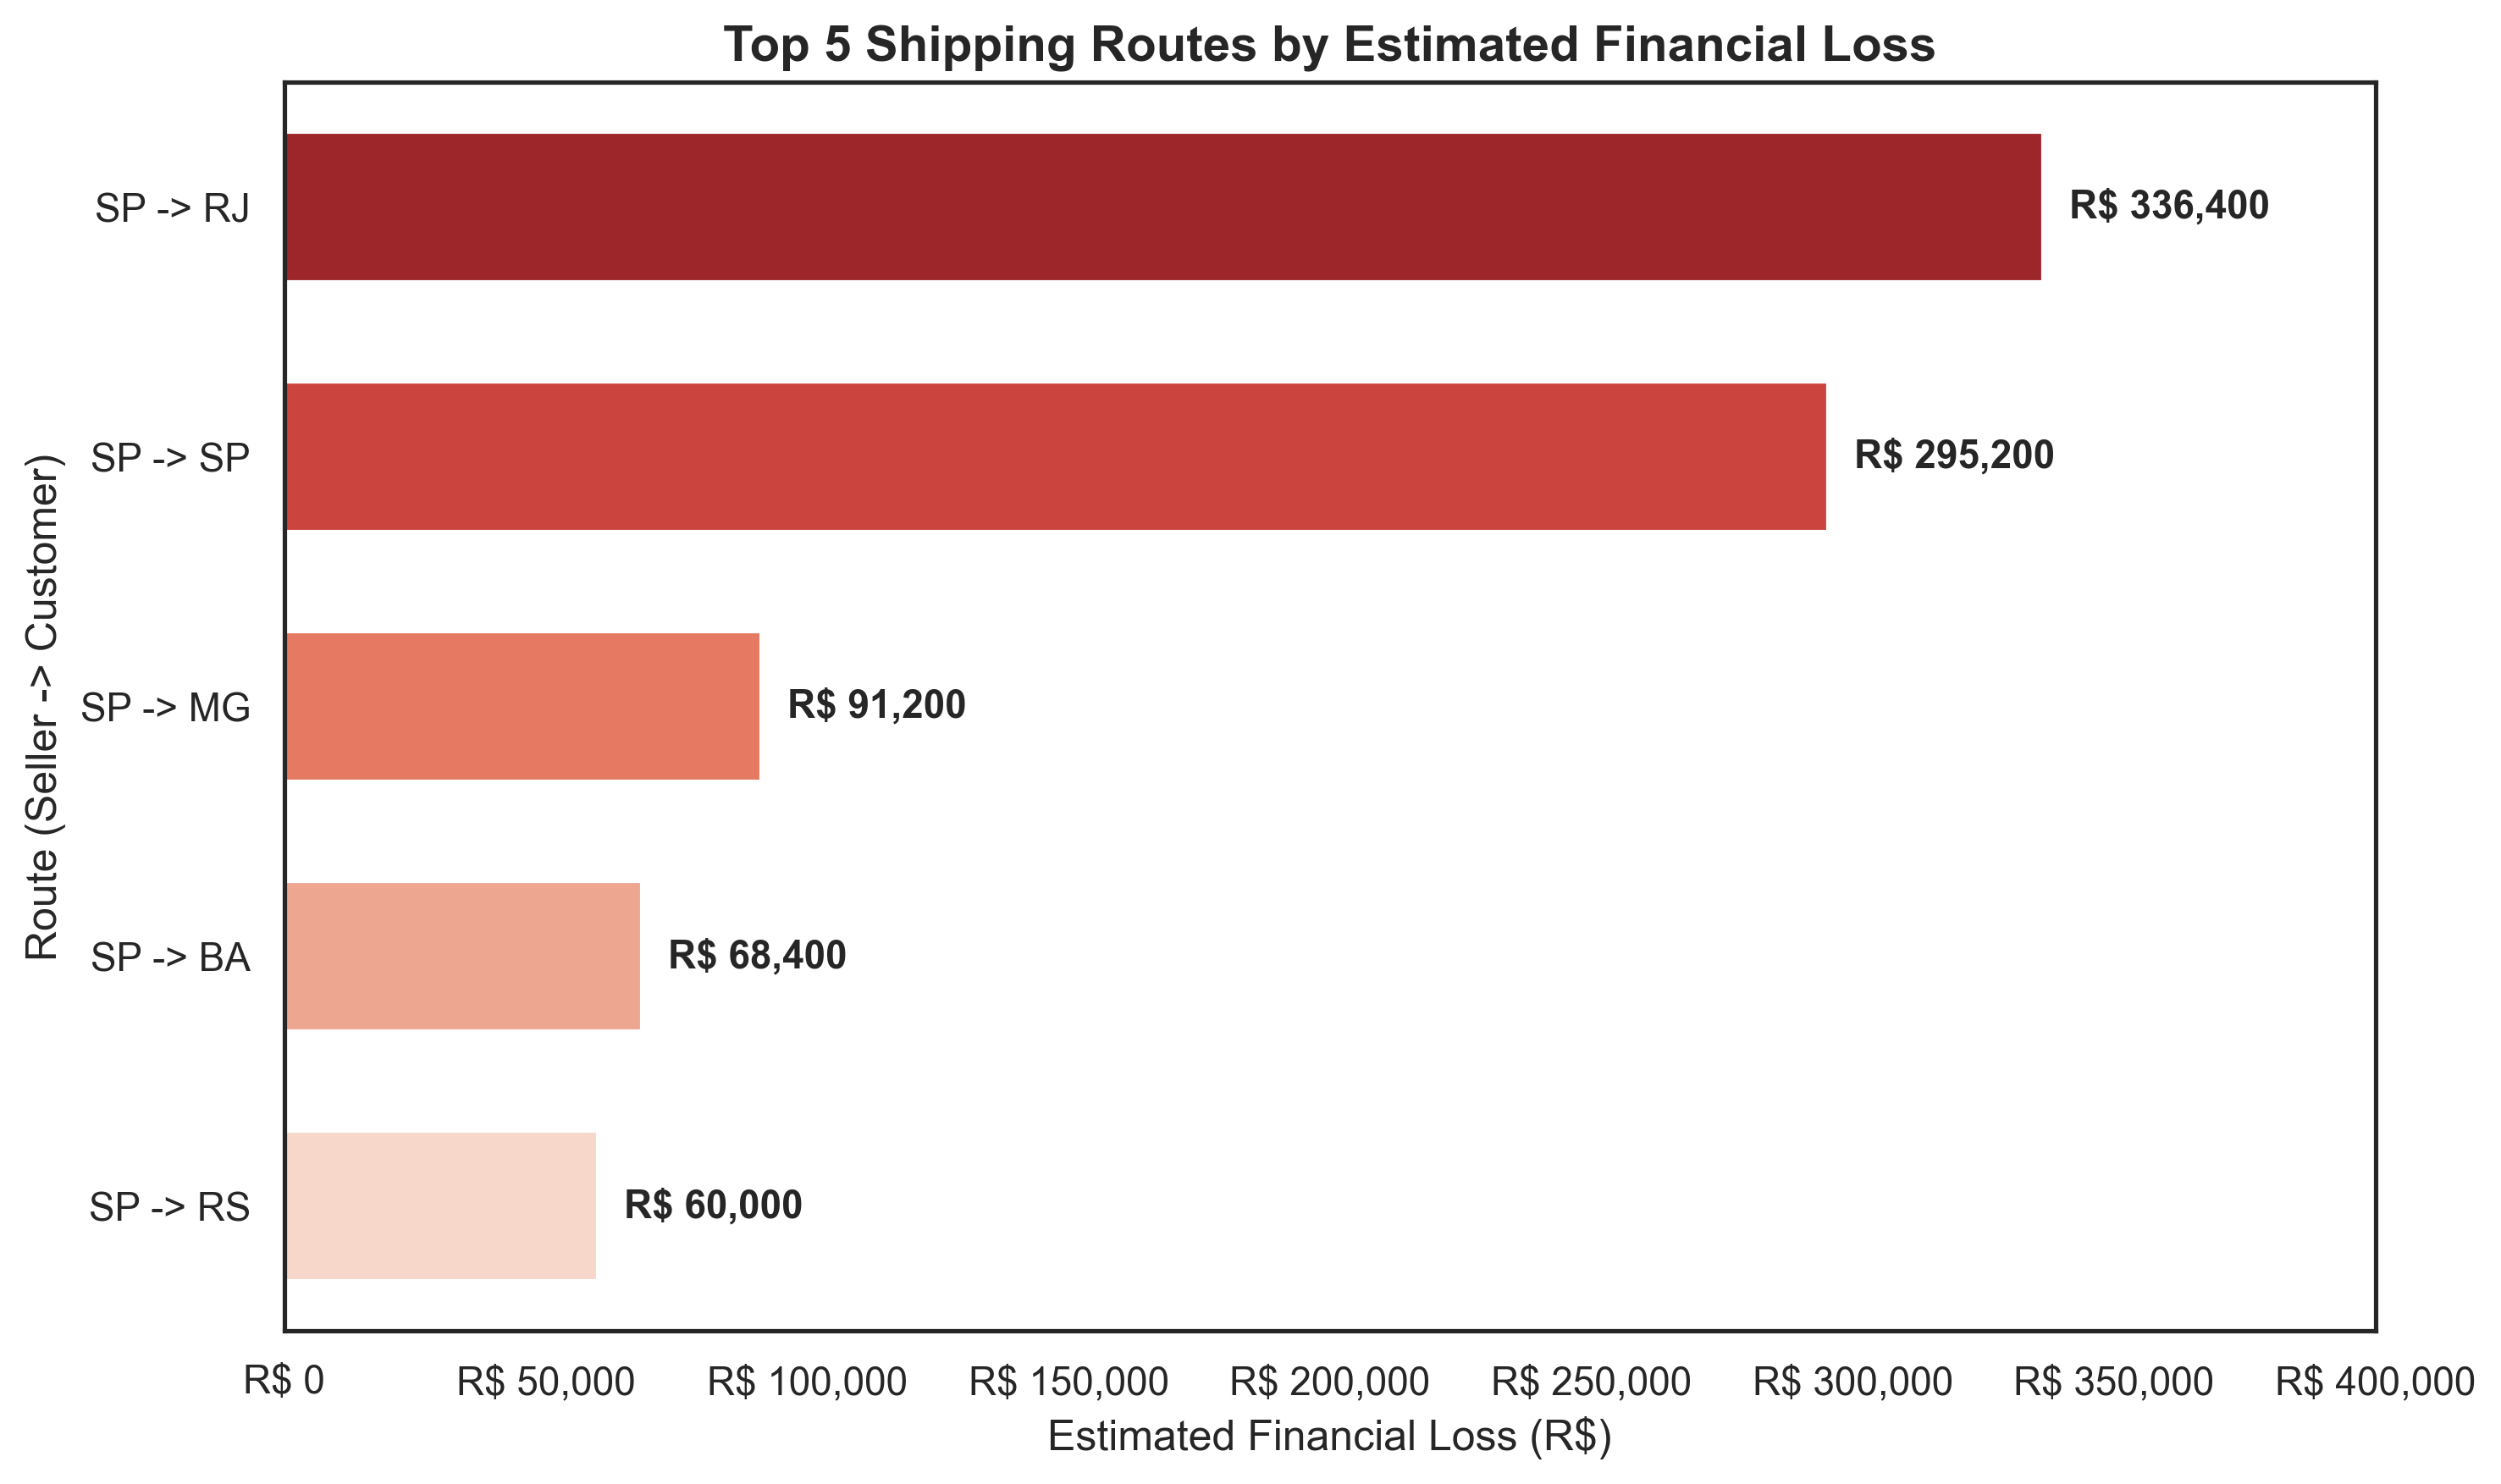

In [13]:
# Financial assumptions
REFUND_COST = 150.00
CLV_LOSS = 250.00
TOTAL_LOSS_PER_REVIEW = REFUND_COST + CLV_LOSS

# Calculate baseline loss
late_bad_reviews = df[(df['is_late'] == 1) & (df['review_score'] <= 2)].copy()
total_loss = len(late_bad_reviews) * TOTAL_LOSS_PER_REVIEW

print(f"Total Estimated Financial Loss: R$ {total_loss:,.2f}")

# Group by route to find absolute financial loss
route_loss = late_bad_reviews.groupby('route').agg(
    bad_reviews=('review_score', 'count')
).reset_index()
route_loss['financial_loss'] = route_loss['bad_reviews'] * TOTAL_LOSS_PER_REVIEW
route_loss = route_loss.sort_values('financial_loss', ascending=False)

# ROI Simulation
worst_route = route_loss.iloc[0]
route_name = worst_route['route']
bad_reviews_on_route = worst_route['bad_reviews']

saved_reviews = int(bad_reviews_on_route * 0.25)
money_saved = saved_reviews * TOTAL_LOSS_PER_REVIEW

print(f"Worst Route: {route_name} (Loss: R$ {worst_route['financial_loss']:,.2f})")
print(f"Estimated Savings by fixing {route_name} by 25%: R$ {money_saved:,.2f}")

# Visualization 5: Top 5 Worst Routes by Financial Loss (FIXED ALIGNMENT)
top_5_routes = route_loss.head(5)
plt.figure(figsize=(10, 6))
sns.barplot(x='financial_loss', y='route', data=top_5_routes, hue='route', palette='Reds_r', dodge=False, width=0.6)
plt.legend([],[], frameon=False)

plt.title('Top 5 Shipping Routes by Estimated Financial Loss', fontsize=14, fontweight='bold')
plt.xlabel('Estimated Financial Loss (R$)', fontsize=12)
plt.ylabel('Route (Seller -> Customer)', fontsize=12)
plt.gca().xaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'R$ {x:,.0f}'))

# Add an explicit offset to the text so it's not cramped
for index, value in enumerate(top_5_routes['financial_loss']):
    plt.text(value + 5000, index, f'R$ {value:,.0f}', va='center', fontweight='bold', fontsize=11)

# Increase the x-axis limit to give the text room to breathe
plt.xlim(0, 400000) 

plt.tight_layout()
plt.savefig('../visualizations/fig5_financial_impact.png', dpi=300)
plt.show()

## 7. Conclusion & Business Recommendations

This study empirically proved that late deliveries severely impact customer satisfaction and directly hurt revenue. 

### Key Findings:
*   **Customer Impact:** Late deliveries drop customer ratings from 4.29 to 2.27 (a "large" effect size, Cliff's Delta = -0.637).
*   **Operational Bottleneck:** While `SP -> AL` has the highest percentage of delays (23.9%), the `SP -> RJ` route is the most damaging overall due to its massive volume (1,152 late orders).
*   **Predictive Power:** A Random Forest model (AUC = 0.68) can predict late deliveries using only checkout data. The top driver of delays is the geographical distance (`customer_state`) and the promised delivery window (`estimated_shipping_days`).

### Financial Impact & Recommendation:
Late deliveries resulting in bad reviews cost the company an estimated **R$ 1,592,000**. 

**Management Recommendation:** If the logistics team implements a targeted intervention to reduce delays on the worst route (**SP -> RJ**) by just **25%**, the company will prevent **210 bad customer experiences** and save **R$ 84,000** in refunds and lost customer lifetime value.